modele  recall     f1
    E4  0.8826 0.9012
    E6  0.7461 0.8260
    E7  0.8325 0.8740
    M4  0.8964 0.8657


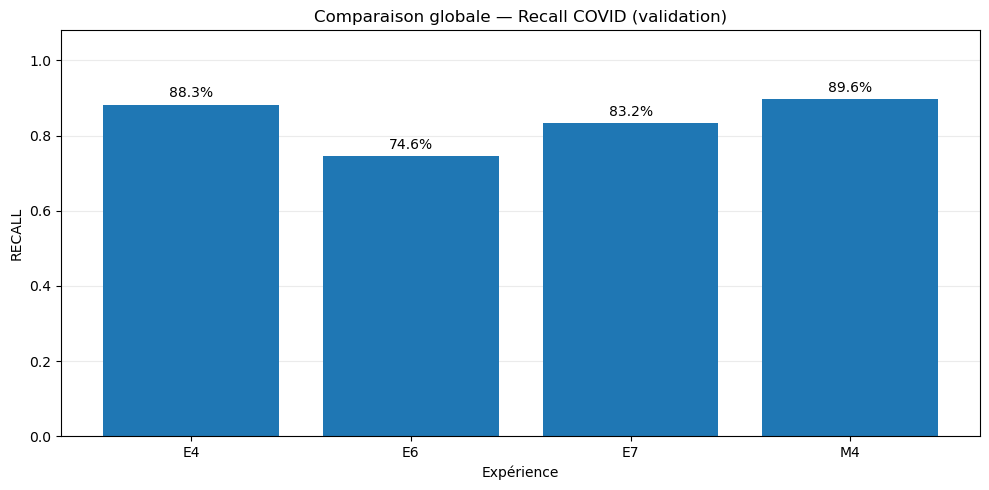

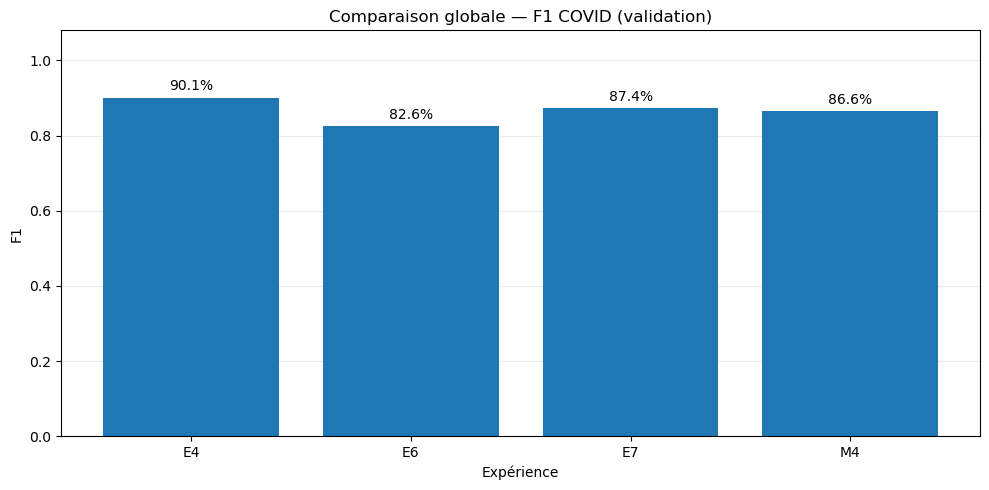

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Fichiers des résultats de validation
# --------------------------------------------------

# Adapter les chemins aux fichiers réellement sauvegardés.
# Chaque CSV doit provenir de classification_report(..., output_dict=True)
# avec les classes en lignes et les métriques en colonnes.

REPORTS = {
    #"E0": {"file": "E0_classification_report.csv", "covid": "1"},
    "E4": {"file": "resultats/e4/E4_VGG16_classification_report_validation.csv", "covid": "COVID"},
    "E6": {"file": "resultats/e6/E6_classification_report.csv", "covid": "COVID"},
    "E7": {"file": "resultats/e7/E7_classification_report.csv", "covid": "COVID"},
    "M4": {"file": "M4_classification_report.csv", "covid": "COVID"},
}

def lire_scores_covid(fichier, classe_covid):
    df = pd.read_csv(fichier, index_col=0)
    df.index = df.index.astype(str).str.strip()

    if classe_covid not in df.index:
        raise ValueError(
            f"{fichier} : classe COVID '{classe_covid}' introuvable. "
            f"Classes disponibles : {df.index.tolist()}"
        )

    return {
        "recall": float(df.loc[classe_covid, "recall"]),
        "f1": float(df.loc[classe_covid, "f1-score"]),
    }

# --------------------------------------------------
# 2. Charger uniquement les résultats disponibles
# --------------------------------------------------

resultats = []

for modele, config in REPORTS.items():
    fichier = Path(config["file"])

    if not fichier.exists():
        print(f"Fichier absent : {fichier} — {modele} ignoré")
        continue

    scores = lire_scores_covid(fichier, config["covid"])

    resultats.append({
        "modele": modele,
        "recall": scores["recall"],
        "f1": scores["f1"],
    })

df_scores = pd.DataFrame(resultats)

if df_scores.empty:
    raise FileNotFoundError(
        "Aucun rapport de classification trouvé. "
        "Vérifie les chemins dans REPORTS."
    )

print(df_scores.round(4).to_string(index=False))

# --------------------------------------------------
# 3. Deux graphiques cross-expériences
# --------------------------------------------------

def graphique_comparatif(df, metrique, titre, nom_fichier):
    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(df["modele"], df[metrique])

    ax.bar_label(
        bars,
        labels=[f"{val:.1%}" for val in df[metrique]],
        padding=3
    )

    ax.set_ylim(0, 1.08)
    ax.set_ylabel(metrique.upper())
    ax.set_xlabel("Expérience")
    ax.set_title(titre)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(nom_fichier, dpi=150, bbox_inches="tight")
    plt.show()


graphique_comparatif(
    df_scores,
    "recall",
    "Comparaison globale — Recall COVID (validation)",
    "Comparaison_globale_recall_COVID.png"
)

graphique_comparatif(
    df_scores,
    "f1",
    "Comparaison globale — F1 COVID (validation)",
    "Comparaison_globale_F1_COVID.png"
)